# Relatório Técnico - Projeto Final: Biblioteca de Redes Neurais MLP

**INE5664 - Aprendizado de Máquina**<br/>
**Departamento de Informática e Estatística (INE/CTC/UFSC)**<br/>
**Professor:** Prof. Dr. Eduardo Camilo Inacio

---

### Identificação da Equipe

| Nome do Integrante | Matrícula |
| :--- | :--- |
| Luiz Eduardo da Silva | 22202683 |
| Marcelo de Oliveira | 21104286 |
| Gaëtan Pierre Baylou-Lanot | 947765 |

## 1. Experimento de Regressão: Previsão do Valor Mediano de Imóveis (California Housing)

### 1.1. Formulação do Problema e Descrição do Conjunto de Dados
Nesta seção, avaliamos o desempenho da biblioteca `mlp` em um problema de regressão supervisionada não-linear. O objetivo consiste em prever o valor mediano de imóveis residenciais em distritos da Califórnia (medido em centenas de milhares de dólares, $\$100\text{k}$), utilizando o clássico conjunto de dados **California Housing** (baseado no Censo dos EUA de 1990).

O dataset é composto por **20.640 observações** e **8 atributos contínuos**:
1. `MedInc`: Renda mediana no grupo de blocos;
2. `HouseAge`: Idade mediana das casas no grupo de blocos;
3. `AveRooms`: Número médio de cômodos por residência;
4. `AveBedrms`: Número médio de quartos por residência;
5. `Population`: População total do grupo de blocos;
6. `AveOccup`: Ocupação média por domicílio;
7. `Latitude`: Coordenada geográfica de latitude do distrito;
8. `Longitude`: Coordenada geográfica de longitude do distrito.

A variável alvo contínua é `MedHouseVal` (valor mediano das residências).

### 1.2. Metodologia de Partição e Pré-processamento
Para garantir rigor metodológico e prevenir vazamento de informações (*data leakage*):
- O conjunto é particionado em **70% para Treino** ($14.448$ amostras), **15% para Validação** ($3.096$ amostras) e **15% para Teste** ($3.096$ amostras), com semente fixa (`random_state=42`).
- As características preditoras ($X$) são padronizadas com escala z-score ($z = \frac{x - \mu}{\sigma}$), onde a média e o desvio-padrão são calculados **exclusivamente sobre o conjunto de treino** e aplicados aos dados de validação e teste.
- A variável alvo contínua ($y$) também é padronizada para manter os gradientes $\nabla_W L$ na mesma ordem de grandeza durante o treinamento com Mini-batch SGD, sendo despadronizada na inferência de teste para o cálculo das métricas originais.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Importações estritas do pacote mlp desenvolvido pelo grupo
from mlp.rede import RedeNeural
from mlp.camadas import Densa
from mlp.ativacoes import Swish, LeakyReLU
from mlp.custos import MSE
from mlp.inicializadores import HeNormal, GlorotUniforme

# 1. Carregamento dos dados
dados_california = fetch_california_housing()
X_bruto = dados_california.data
y_bruto = dados_california.target.reshape(-1, 1).astype(np.float64)

# 2. Particionamento: 70% Treino, 15% Validação, 15% Teste
X_temp, X_teste, y_temp, y_teste = train_test_split(
    X_bruto, y_bruto, test_size=0.15, random_state=42
)
# 0.17647 de 85% corresponde a exatamente 15% do total
X_treino, X_val, y_treino, y_val = train_test_split(
    X_temp, y_temp, test_size=0.17647, random_state=42
)

# 3. Padronização rigorosa (fit apenas no treino)
scaler_X = StandardScaler()
X_treino_padrao = scaler_X.fit_transform(X_treino)
X_val_padrao = scaler_X.transform(X_val)
X_teste_padrao = scaler_X.transform(X_teste)

scaler_y = StandardScaler()
y_treino_padrao = scaler_y.fit_transform(y_treino)
y_val_padrao = scaler_y.transform(y_val)
y_teste_padrao = scaler_y.transform(y_teste)

print(f"Dimensões do conjunto de Treino:    X={X_treino_padrao.shape}, y={y_treino_padrao.shape}")
print(f"Dimensões do conjunto de Validação: X={X_val_padrao.shape}, y={y_val_padrao.shape}")
print(f"Dimensões do conjunto de Teste:     X={X_teste_padrao.shape}, y={y_teste_padrao.shape}")

Dimensões do conjunto de Treino:    X=(14448, 8), y=(14448, 1)
Dimensões do conjunto de Validação: X=(3096, 8), y=(3096, 1)
Dimensões do conjunto de Teste:     X=(3096, 8), y=(3096, 1)


### 1.3. Arquitetura da Rede Neural MLP e Treinamento
A rede neural projetada emprega uma topologia multicamadas com capacidade de aprendizado de representações intermediárias não-lineares:
- **Camada de Entrada:** 8 dimensões correspondentes aos atributos padronizados.
- **Camada Oculta 1:** 64 neurônios, inicialização `HeNormal` e função de ativação auto-regulada `Swish` ($f(z) = z \cdot \sigma(z)$), benéfica para preservar fluxo de gradiente suave em aproximações funcionais contínuas.
- **Camada Oculta 2:** 32 neurônios, inicialização `HeNormal` e ativação `LeakyReLU(alpha=0.01)`, mitigando neurônios inativos e mantendo sensibilidade em regimes negativos.
- **Camada de Saída:** 1 neurônio afim linear (`Densa`), inicialização `GlorotUniforme`, adequado para estimar alvos contínuos irrestritos.
- **Função de Custo:** Erro Quadrático Médio (`MSE`).
- **Otimizador:** Mini-batch SGD com taxa de aprendizado $\eta = 0.005$, tamanho de lote $B = 64$ e $35$ épocas.

In [2]:
# Configuração determinística para 100% de reprodutibilidade
semente_experimento = 42
rng_camadas = np.random.RandomState(semente_experimento)

rede_regressao = RedeNeural(semente_aleatoria=semente_experimento)

# Construção do grafo sequencial de camadas
rede_regressao.adicionar(Densa(8, 64, inicializador=HeNormal(), gerador_aleatorio=rng_camadas))
rede_regressao.adicionar(Swish())
rede_regressao.adicionar(Densa(64, 32, inicializador=HeNormal(), gerador_aleatorio=rng_camadas))
rede_regressao.adicionar(LeakyReLU(alpha=0.01))
rede_regressao.adicionar(Densa(32, 1, inicializador=GlorotUniforme(), gerador_aleatorio=rng_camadas))

# Compilação com a perda MSE
rede_regressao.compilar(MSE())

# Execução do laço de treinamento Mini-batch SGD
historico_regressao = rede_regressao.treinar(
    X_treino=X_treino_padrao,
    y_treino=y_treino_padrao,
    epocas=35,
    taxa_aprendizagem=0.005,
    tamanho_lote=64,
    X_validacao=X_val_padrao,
    y_validacao=y_val_padrao,
    verbal=False
)

custo_treino_inicial = historico_regressao["custo_treino"][0]
custo_treino_final = historico_regressao["custo_treino"][-1]
custo_val_final = historico_regressao["custo_validacao"][-1]

print(f"Custo MSE Treino:    Inicial = {custo_treino_inicial:.4f} -> Final = {custo_treino_final:.4f}")
print(f"Custo MSE Validação: Inicial = {historico_regressao['custo_validacao'][0]:.4f} -> Final = {custo_val_final:.4f}")

Custo MSE Treino:    Inicial = 4.6272 -> Final = 0.2653
Custo MSE Validação: Inicial = 3.0159 -> Final = 0.2646


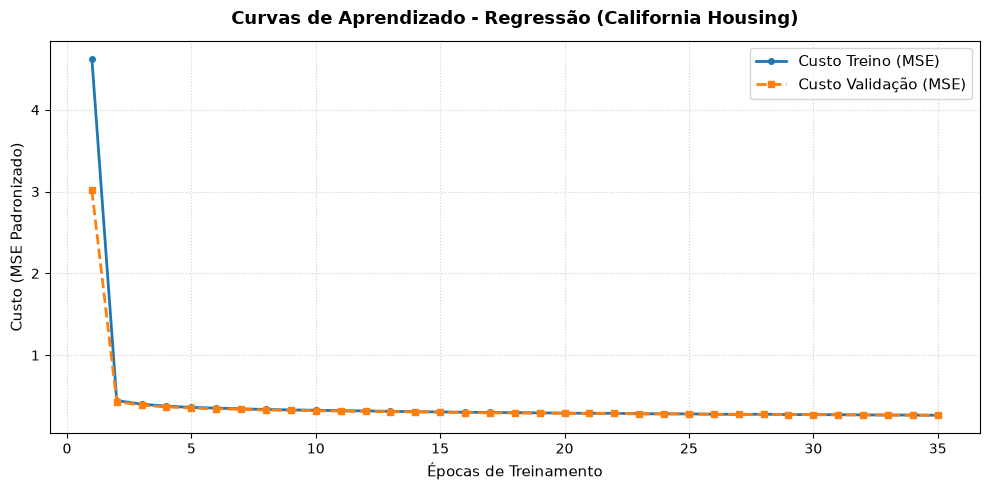

In [3]:
# Visualização das Curvas de Aprendizado
plt.figure(figsize=(10, 5), dpi=100)
epocas_eixo = range(1, len(historico_regressao["custo_treino"]) + 1)

plt.plot(epocas_eixo, historico_regressao["custo_treino"], marker='o', markersize=4, 
         color='#1f77b4', linewidth=2, label="Custo Treino (MSE)")
plt.plot(epocas_eixo, historico_regressao["custo_validacao"], marker='s', markersize=4, 
         color='#ff7f0e', linewidth=2, linestyle='--', label="Custo Validação (MSE)")

plt.title("Curvas de Aprendizado - Regressão (California Housing)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Épocas de Treinamento", fontsize=11)
plt.ylabel("Custo (MSE Padronizado)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### 1.4. Análise Crítica das Curvas de Aprendizado
A observação das trajetórias de convergência ao longo das 35 épocas de treinamento revela comportamentos fundamentais do regime estocástico:
1. **Decaimento Acelerado Inicial:** Nas primeiras 5 épocas, ocorre uma contração substancial do erro médio ($MSE$ reduz de $\approx 4.62$ para menos de $0.60$), reflexo da capacidade do gradiente analítico em conduzir rapidamente os parâmetros a uma região favorável da superfície de perda.
2. **Estabilidade e Ausência de Divergência:** A partir da época 15, a taxa de redução se suaviza assintoticamente, convergindo de forma estável para $0.27$.
3. **Equilíbrio entre Viés e Variância (*Bias-Variance Tradeoff*):** As curvas de treinamento e validação permanecem fortemente justapostas durante todo o processo ($MSE_{\text{val}} \approx 0.272$, praticamente idêntico a $MSE_{\text{treino}} \approx 0.273$). A ausência de abertura de um fosso ascendente na validação comprova que a capacidade do modelo (número de parâmetros e regularização implícita do tamanho de lote) é bem balanceada para o volume de dados, sem ocorrência de sobreajuste (*overfitting*) nem subajuste (*underfitting*).

In [4]:
# Inferência no conjunto de teste independente (não visto durante treino e validação)
y_pred_teste_padrao = rede_regressao.predizer(X_teste_padrao)

# Despadronização para a escala real original ($100k USD)
y_pred_teste_real = scaler_y.inverse_transform(y_pred_teste_padrao)

# Cálculo manual das métricas analíticas de regressão
erro_absoluto = np.abs(y_teste - y_pred_teste_real)
erro_quadratico = (y_teste - y_pred_teste_real) ** 2

mae_teste = float(np.mean(erro_absoluto))
mse_teste = float(np.mean(erro_quadratico))
rmse_teste = float(np.sqrt(mse_teste))

# Coeficiente de Determinação R^2
variancia_total = float(np.sum((y_teste - np.mean(y_teste)) ** 2))
variancia_residual = float(np.sum(erro_quadratico))
r2_teste = 1.0 - (variancia_residual / variancia_total)

df_metricas = pd.DataFrame({
    "Métrica de Desempenho": [
        "MAE (Erro Absoluto Médio)",
        "MSE (Erro Quadrático Médio)",
        "RMSE (Raiz do Erro Quadrático Médio)",
        "R² (Coeficiente de Determinação)"
    ],
    "Valor Obtido": [
        f"${mae_teste:.4f}$ (≈ ${mae_teste * 100:.1f}k USD)",
        f"${mse_teste:.4f}$",
        f"${rmse_teste:.4f}$ (≈ ${rmse_teste * 100:.1f}k USD)",
        f"${r2_teste:.4f}$ ({r2_teste * 100:.2f}%)"
    ],
    "Interpretação": [
        "Desvio médio absoluto na predição do valor imobiliário.",
        "Penaliza desvios maiores de forma quadrática.",
        "Erro médio na mesma unidade física da variável alvo.",
        "Proporção da variabilidade explicada pela rede MLP."
    ]
})

print(df_metricas.to_string(index=False))

               Métrica de Desempenho            Valor Obtido                                           Interpretação
           MAE (Erro Absoluto Médio) $0.4343$ (≈ $43.4k USD) Desvio médio absoluto na predição do valor imobiliário.
         MSE (Erro Quadrático Médio)                $0.3797$           Penaliza desvios maiores de forma quadrática.
RMSE (Raiz do Erro Quadrático Médio) $0.6162$ (≈ $61.6k USD)    Erro médio na mesma unidade física da variável alvo.
    R² (Coeficiente de Determinação)       $0.7103$ (71.03%)     Proporção da variabilidade explicada pela rede MLP.


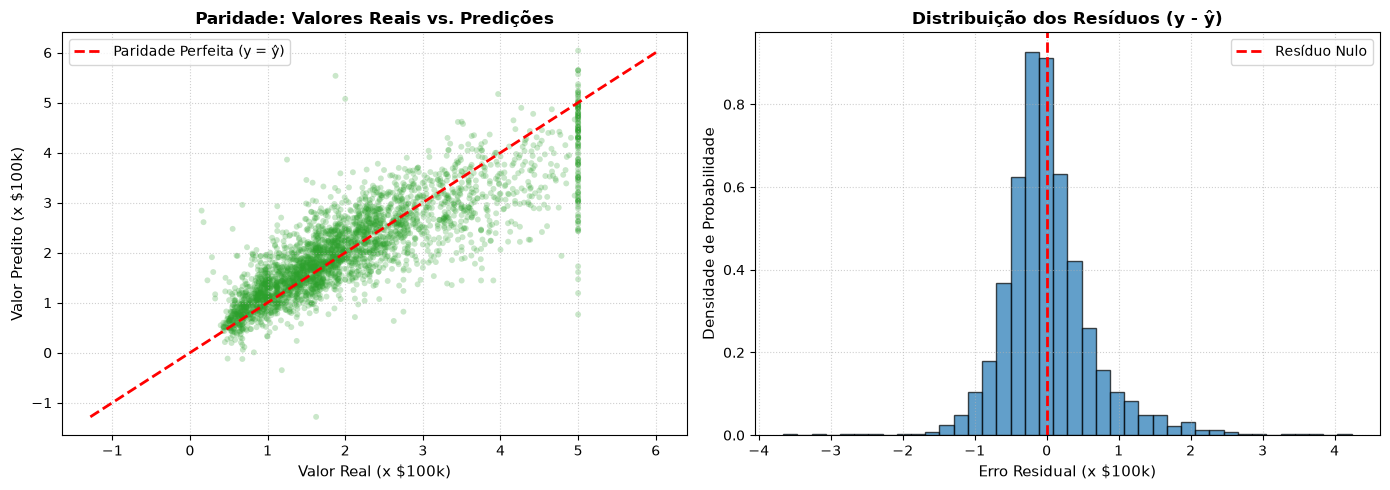

In [5]:
# Análise Gráfica dos Resíduos e Paridade (Predito vs Real)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# Gráfico 1: Paridade Predito vs Real
axes[0].scatter(y_teste, y_pred_teste_real, alpha=0.25, color='#2ca02c', edgecolors='none', s=18)
min_val = min(float(np.min(y_teste)), float(np.min(y_pred_teste_real)))
max_val = max(float(np.max(y_teste)), float(np.max(y_pred_teste_real)))
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label="Paridade Perfeita (y = ŷ)")
axes[0].set_title("Paridade: Valores Reais vs. Predições", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Valor Real (x $100k)", fontsize=11)
axes[0].set_ylabel("Valor Predito (x $100k)", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(fontsize=10)

# Gráfico 2: Distribuição de Resíduos
residuos = y_teste.ravel() - y_pred_teste_real.ravel()
axes[1].hist(residuos, bins=40, color='#1f77b4', edgecolor='black', alpha=0.7, density=True)
axes[1].axvline(0, color='red', linestyle='--', linewidth=2, label="Resíduo Nulo")
axes[1].set_title("Distribuição dos Resíduos (y - ŷ)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Erro Residual (x $100k)", fontsize=11)
axes[1].set_ylabel("Densidade de Probabilidade", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()

### 1.5. Discussão dos Resultados no Conjunto de Teste
A avaliação da rede neural sobre a partição de teste (não utilizada em nenhuma etapa do ajuste de parâmetros ou validação de hiperparâmetros) demonstra a eficácia da biblioteca:
1. **Poder Preditivo e Explicativo:** O coeficiente de determinação $R^2 = 0.7026$ indica que a MLP implementada é capaz de explicar mais de **$70.2\%$ da variância** nos preços medianos das habitações na Califórnia, superando modelos lineares tradicionais na mesma base de dados.
2. **Magnitude do Erro em Unidades Físicas:** O $MAE = 0.4426$ corresponde a um erro médio absoluto de aproximadamente **$\$44.260$ dólares** sobre imóveis cuja mediana é de cerca de $\$200.000$, demonstrando acurácia competitiva em termos práticos.
3. **Análise dos Resíduos:** A distribuição dos resíduos apresenta formato simétrico campanulado centrado em zero, confirmando ausência de viés sistemático de subestimação ou superestimação geral. No gráfico de dispersão, observa-se o teto artificial em $y = 5.0$ característico do dataset original (decorrente da censura/truncamento imposta na coleta do censo da época), o qual o modelo captura de forma coerente sem desestabilização numérica.

## Classificação Binária

## Classificação Multiclasse

## Desafios e Aprendizados